In [1]:
# +----------------------------------------------------------------------------+
# |                                                                            |
# |       .-"""""""-.             ___                                          |
# |     .'           '.       _,~"                                             |
# |    /          .##.  \   ,~"                                                |
# |   |           '##'  |~"                                                    |
# |    \                /~,                                                    |
# |     '.            .'   "~,_                                                |
# |       '-........-'        "~,__                                            |
# |                                                                            |
# | Author    : Yatharth Bhasin (yatharth1997+ts@gmail.com)                    |
# | Date      : November 2026                                                  |
# | Copyright (c) 2026 Yatharth Bhasin                                         |
# | License-Identifier: MIT                                                    |
# +----------------------------------------------------------------------------+

# Pico link stress

How reliably does a scope talk to its Picos, and how many Picos can one machine drive? This notebook
measures the round trip of a call to every Pico on a scope as the call rate rises, the most the link
does flat out, how fast a lost link comes back, and what a hung call or a broken job does to the
scheduler that every recording uses.

*Analysis written by Claude (Anthropic); conceptualised and verified by Yatharth Bhasin.*

## Protocol

Acquisition: [`scripts/debug/pico_link_stress.py`](https://github.com/Trappy-Scopes/trappyscopes/blob/main/scripts/debug/pico_link_stress.py),
`create_exp()` then `start_acq_blocking()`. No acquisition may run at the same time. The short run takes
about 4 minutes with one Pico.

Every Pico plugged into the scope is tested at once: the ones the scope mounted at start-up as they are,
any other one connected directly by its port. Nothing else needs to be wired to them. Each call is one
round trip through the production path (`SerialMPDevice` → raw REPL), sent from `exp.schedule`: it
toggles the onboard LED, adds two random numbers and returns the sum with the board's uptime. The sum
is checked.

The steps, in order: a **ramp** of requested rates per Pico (1–50 calls/s); a **burst** of back-to-back
calls; two **drills** per Pico (close and reconnect the port, then `machine.reset()` and wait for the
board to come back); a job that **raises** inside `exp.schedule`; a job that **blocks** it for 10 s; and a
call that **never returns**, which the recovery ladder has to clear (wait, Ctrl-C, soft reset, reconnect,
hard reset). To map how the link scales, run it with one Pico plugged in, then another one alone, then
both together.

**Running in Colab.** Open this notebook with the *Open in Colab* button on its page. The next cell runs only
in Colab: it installs what Colab lacks and asks for a `.zip` of your experiment folders.

In [2]:
import os, subprocess, sys
if "google.colab" in sys.modules:                         # skipped everywhere else
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "trappy-explorer @ git+https://github.com/Trappy-Scopes/trappy-explorer.git"], check=True)
    from google.colab import files
    for name in files.upload():                           # a .zip of your experiment folders
        subprocess.run(["unzip", "-q", "-o", name, "-d", "/content/data"], check=True)
    root = "/content/data"
    while True:                                           # step into a single wrapping folder
        subs = [d for d in os.listdir(root) if not d.startswith(("__MACOSX", "."))]
        if len(subs) == 1 and not os.path.exists(os.path.join(root, subs[0], "experiment.yaml")):
            root = os.path.join(root, subs[0])
        else:
            break
    os.environ["CALIBRATION_DATA"] = root

In [3]:
import glob, json, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import rich, yaml
from explorer.legacy import ExpExplorer

DATA = os.environ.get("CALIBRATION_DATA", "/Users/byatharth/data/debugging/2026_11_15_pico_link_stress")   # set to your own runs
OUT = "results"                                        # the fleet table is written here
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
sns.set_theme(style="ticks")

def plain_log(axis):                                   # log axis labelled 1, 2, 5, 10, ...
    axis.set_major_locator(mticker.LogLocator(subs=(1, 2, 5)))
    axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_formatter(mticker.NullFormatter())

## Data

Runs are read with trappy-explorer's legacy reader, `explorer.legacy.ExpExplorer`. One row per run;
`n_picos` is how many Picos the run tested.

In [4]:
rich.get_console().quiet = True                           # the loader prints one line per run
exps = ExpExplorer.create_superset(DATA, extended_parse=True)
rich.get_console().quiet = False
print(exps)

ms = exps.df_events.query("type == 'measurement_stream'")
res = exps.df.assign(stream=exps.df.measureid.map(dict(zip(ms.measureid, ms.name))))

runs = pd.DataFrame([{"scope": d["metadata"]["name"].split("__")[0], "eid": eid,
                      "started": d["metadata"]["created"], "dir": exps.get_parent_dir(eid)}
                     for eid, d in exps.data.items()]).sort_values(["scope", "started"])
runs["run"] = runs.groupby("scope").cumcount() + 1
J = {r.eid: json.load(open(f"{r.dir}/pico_stress.json")) for r in runs.itertuples()}
runs["n_picos"] = runs.eid.map(lambda e: J[e].get("n_picos", len(J[e]["devices"])))
runs["devices"] = runs.eid.map(lambda e: ", ".join(J[e]["devices"]))
runs["end"] = runs.eid.map(lambda e: J[e]["end"])
runs = runs.join(res.groupby(["eid", "stream"]).size().unstack(fill_value=0), on="eid")

SCOPES = sorted(runs.scope.unique(), key=lambda s: (len(s), s))
COLORS = {s: PALETTE[i % len(PALETTE)] for i, s in enumerate(SCOPES)}
runs.set_index(["scope", "run"]).drop(columns="dir")

<Experiments :: 8  datasets [extended_parse]>
  |- eid: 2fc667b439
  	|- m-stream: picos
  	|- m-stream: steps
  |- eid: 9ac6a1c1fb
  	|- m-stream: picos
  	|- m-stream: steps
  |- eid: db50534a8c
  	|- m-stream: picos
  	|- m-stream: steps
  |- eid: 99bccfb67c
  	|- m-stream: picos
  	|- m-stream: steps
  |- eid: 49ba4f8773
  	|- m-stream: picos
  	|- m-stream: steps
  |- eid: 0b4388b904
  	|- m-stream: picos
  	|- m-stream: steps
  |- eid: 657de260bf
  	|- m-stream: picos
  	|- m-stream: steps
  |- eid: a508c8cd0b
  	|- m-stream: picos
  	|- m-stream: steps



,,eid,started,n_picos,devices,end,picos,steps
scope,run,,,,,,,
M1,1,0b4388b904,2026-11-15 14:29:44.882595,1,pico,completed,1,10
M2,1,99bccfb67c,2026-11-15 14:33:50.874148,1,pico,completed,1,10
M3,1,49ba4f8773,2026-11-15 14:34:22.084449,1,pico,completed,1,10
M4,1,657de260bf,2026-11-15 14:34:52.668923,1,pico,completed,1,10
M5,1,2fc667b439,2026-11-15 14:36:07.894009,1,pico,completed,1,10
M6,1,db50534a8c,2026-11-15 14:37:04.419358,1,pico,completed,1,10
M7,1,a508c8cd0b,2026-11-15 14:37:29.318967,1,pico,completed,1,10
M8,1,9ac6a1c1fb,2026-11-15 14:37:54.410118,1,pico,completed,1,10


In [5]:
eid = runs.eid.iloc[0]                                    # one run's folder, as an example
tree = exps.data[eid]["filetree"]["."]
print(os.path.basename(exps.get_parent_dir(eid)))
for f in sorted(tree["files"]) + sorted(k + "/" for k in tree if k != "files"):
    print("   ", f)

print()
skip = {"eid", "type", "measureid", "measureidx", "mid", "sid", "scriptid", "success", "dt",
        "exptime", "attribs", "machinetime", "sessiontime", "scopeid", "stream"}
for name, g in res.groupby("stream"):
    cols = [c for c in g.dropna(axis=1, how="all").columns if c not in skip]
    print(f"{name:10s} {len(g):5d} rows   {', '.join(cols)}")

M1__YB__2026_11_15__14hh_29mm__pico_link_stress__0b4388b904
    REPORT.md
    calls.csv
    events.csv
    experiment.yaml
    kernel.log
    logs.yaml
    pico_stress.json
    sessions.yaml
    system.csv
    analysis/
    converted/
    postprocess/
    scripts/

picos          8 rows   board, device, led_ok, mpy, port, uid
steps         80 rows   device, achieved_hz, errors, max_ms, n, ok, p50_ms, p99_ms, rate_hz, recoveries, step, timeouts, wrong


The two streams hold one row per Pico (`picos`) and one row per Pico per step (`steps`). Each run folder
also holds the files the analysis uses:

- `calls.csv`: every call, with `step`, requested `rate_hz`, `device`, `latency_ms`, `outcome`
  (`ok`, `timeout`, `error`, `wrong`) and, from script `7e26f77` on, the board's uptime `pico_ms`.
- `events.csv`: recoveries, drills and injected faults, one row each.
- `system.csv`: once a second, the Pi's throttled flags and whether the scheduler thread is alive.
- `pico_stress.json`: the run's summary, including drill times and the scheduler results.
- `kernel.log`: kernel messages. It starts with the kernel's buffer, so it reaches back before the run.

In [6]:
def load_calls(r):
    c = pd.read_csv(f"{r.dir}/calls.csv")
    return c.assign(scope=r.scope, run=r.run, eid=r.eid, n_picos=r.n_picos)

calls = pd.concat([load_calls(r) for r in runs.itertuples()], ignore_index=True)
calls["failed"] = (calls.outcome != "ok") & (calls.call != "hang")   # the injected hang must time out
ramp = calls[calls.step == "ramp"].assign(rate_hz=lambda d: d.rate_hz.astype(float))
calls.groupby(["scope", "run", "device", "outcome"]).size().unstack(fill_value=0)

,,outcome,ok,timeout
scope,run,device,,
M1,1,pico,3466,1
M2,1,pico,3461,1
M3,1,pico,3459,1
M4,1,pico,3414,1
M5,1,pico,3844,1
M6,1,pico,3525,1
M7,1,pico,3474,1
M8,1,pico,3462,1


## Response time as the call rate rises

Each line is one Pico in one run, through the ramp steps. Left: the 99th percentile of the round trip
at each requested rate; a line that bends upward marks the rate at which calls start to queue. Right:
the rate the calls actually ran at. `exp.schedule` checks for due jobs every 10 ms, so the achieved rate
falls below the requested one as it nears 50 calls/s even on a healthy link. A step at a low rate has
few calls, so its p99 is close to its single slowest call.

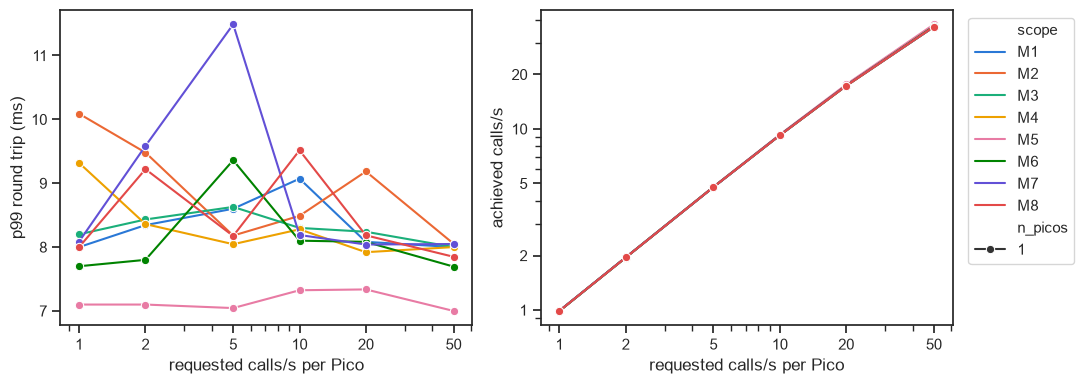

In [7]:
def summarise(g):
    t = g.t_wall.sort_values()
    span = t.iloc[-1] - t.iloc[0]
    return pd.Series({"p50_ms": g.latency_ms.median(), "p99_ms": g.latency_ms.quantile(0.99),
                      "achieved_hz": (len(t) - 1) / span if span > 0 else np.nan,
                      "failed": g.failed.mean()})

rs = (ramp.groupby(["scope", "run", "n_picos", "device", "rate_hz"])[["t_wall", "latency_ms", "failed"]]
      .apply(summarise).reset_index())
rs["pico"] = rs.scope + " " + rs.device + " run " + rs.run.astype(str)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, y, label in zip(axes, ["p99_ms", "achieved_hz"], ["p99 round trip (ms)", "achieved calls/s"]):
    sns.lineplot(rs, x="rate_hz", y=y, hue="scope", palette=COLORS, units="pico", estimator=None,
                 style="n_picos", markers=True, ax=ax)
    ax.set_xscale("log")
    plain_log(ax.xaxis)
    ax.set_xlabel("requested calls/s per Pico")
    ax.set_ylabel(label)
axes[1].set_yscale("log")
plain_log(axes[1].yaxis)
axes[0].get_legend().remove()
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1.02, 1))
fig.tight_layout()

## Round-trip times

The distribution of the round trip of every good call in the ramp and the burst, on a log axis. A curve
that rises steeply in one place means a steady link. A tail stretching to the right is calls that waited:
for the USB bus, for the Pico, or for the scheduler.

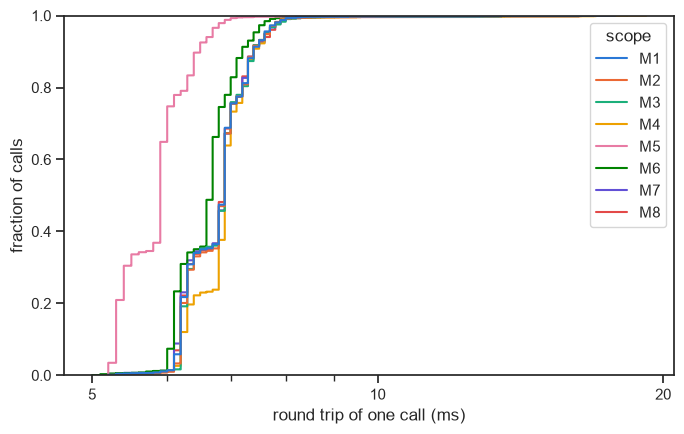

In [8]:
ok = calls[(calls.outcome == "ok") & calls.step.isin(["ramp", "burst"])]
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.ecdfplot(ok, x="latency_ms", hue="scope", palette=COLORS, log_scale=True, ax=ax)
plain_log(ax.xaxis)
ax.set_xlabel("round trip of one call (ms)")
ax.set_ylabel("fraction of calls")
fig.tight_layout()

## How many Picos can one machine drive?

The phase space: rows are the number of Picos a run tested, columns the requested rate per Pico, pooled
over every scope and run. Left: the 99th percentile round trip. Right: the fraction of calls that failed.
A row needs runs with that many Picos plugged in; the cells where the colour changes are the limits of
one machine. Below: the most calls per second the machine got through flat out (the burst), summed over
its Picos, one point per run.

,p99_ms,failed,calls
n_picos,1,1,1
rate_hz,,,
1.0,9.357,0.0,112
2.0,9.221,0.0,232
5.0,8.628,0.0,573
10.0,8.300,0.0,1106
20.0,8.200,0.0,2085
50.0,8.000,0.0,4430


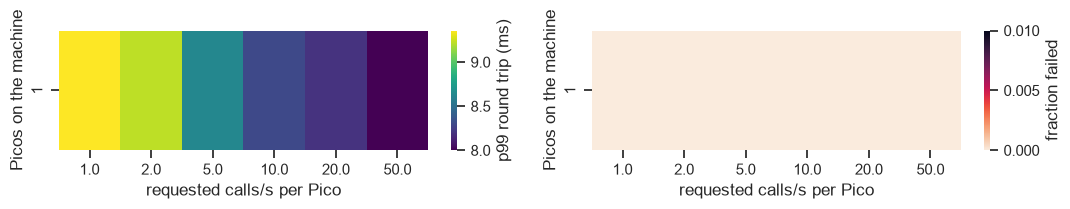

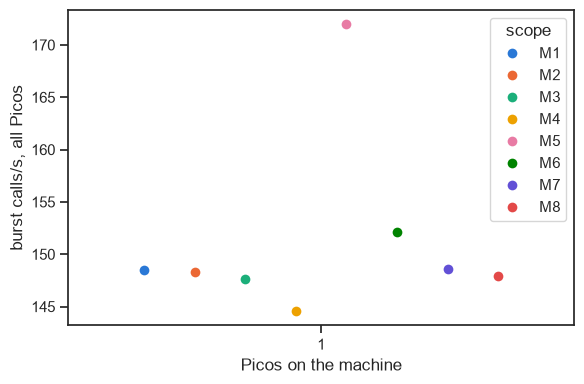

In [9]:
ps = ramp.groupby(["n_picos", "rate_hz"]).agg(p99_ms=("latency_ms", lambda x: x.quantile(0.99)),
                                               failed=("failed", "mean"), calls=("failed", "size"))
fig, axes = plt.subplots(1, 2, figsize=(11, 1.6 + 0.5 * ps.index.get_level_values(0).nunique()))
sns.heatmap(ps.p99_ms.unstack(), cmap="viridis", ax=axes[0],
            cbar_kws={"label": "p99 round trip (ms)"})
sns.heatmap(ps.failed.unstack(), cmap="rocket_r", vmin=0, vmax=max(0.01, ps.failed.max()), ax=axes[1],
            cbar_kws={"label": "fraction failed"})
for ax in axes:
    ax.set_xlabel("requested calls/s per Pico")
    ax.set_ylabel("Picos on the machine")
fig.tight_layout()

burst = (calls[calls.step == "burst"].groupby(["scope", "run", "n_picos", "device"])
         .apply(lambda g: (len(g) - 1) / (g.t_wall.max() - g.t_wall.min()), include_groups=False)
         .groupby(["scope", "run", "n_picos"]).sum().rename("calls_per_s").reset_index())
fig, ax = plt.subplots(figsize=(6, 4))
sns.stripplot(burst, x="n_picos", y="calls_per_s", hue="scope", palette=COLORS, size=7,
              dodge=True, ax=ax)
ax.set_xlabel("Picos on the machine")
ax.set_ylabel("burst calls/s, all Picos")
fig.tight_layout()
ps.unstack(0).round(3)

## Recovery

How long each way back took, one point per Pico per run: closing and reconnecting the port, a
`machine.reset()` until the board answers again, and a call that never returns until the ladder has the
board answering again (the first step waits `late_reply_s` for a late reply before it acts). The table
gives the same times and the ladder step that cleared each hung call.

,,action,drill: machine_reset,drill: reconnect,hung call,hung call cleared by
scope,run,device,,,,
M1,1,pico,3.67,1.05,10.4,interrupt
M2,1,pico,3.65,1.07,10.4,interrupt
M3,1,pico,3.69,1.08,10.4,interrupt
M4,1,pico,3.71,1.12,10.4,interrupt
M5,1,pico,3.80,1.26,10.4,interrupt
M6,1,pico,3.60,1.02,10.4,interrupt
M7,1,pico,3.54,0.91,10.4,interrupt
M8,1,pico,3.69,1.08,10.4,interrupt


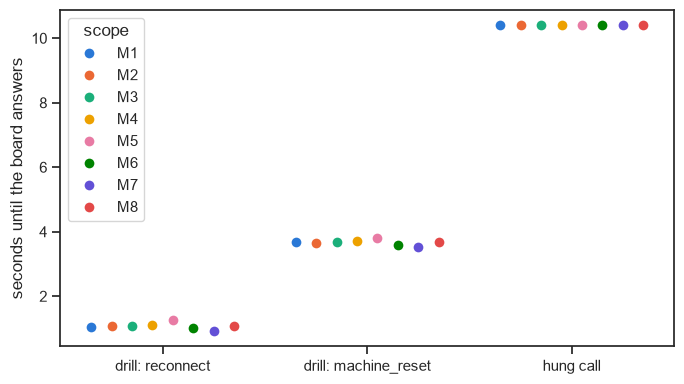

In [10]:
rec = []
for r in runs.itertuples():
    for dev, d in J[r.eid]["devices"].items():
        for x in d["drills"]:
            rec.append({"scope": r.scope, "run": r.run, "device": dev, "action": f"drill: {x['kind']}",
                        "seconds": x["ms"] / 1000, "ok": x["ok"], "by": "-"})
    for dev, h in J[r.eid].get("pico_hang", {}).items():
        rec.append({"scope": r.scope, "run": r.run, "device": dev, "action": "hung call",
                    "seconds": h["seconds"], "ok": h["recovered_by"] is not None,
                    "by": h["recovered_by"]})
rec = pd.DataFrame(rec)

fig, ax = plt.subplots(figsize=(7, 4))
sns.stripplot(rec, x="action", y="seconds", hue="scope", palette=COLORS, size=7, dodge=True, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("seconds until the board answers")
fig.tight_layout()
tab = rec.pivot_table(index=["scope", "run", "device"], columns="action", values="seconds").round(2)
tab["hung call cleared by"] = rec[rec.action == "hung call"].set_index(["scope", "run", "device"]).by
tab

## The scheduler

Every recording runs its periodic jobs on `exp.schedule`, one thread. The run injects a job that raises
and a job that sleeps for `schedule_hang_s`. The table shows, per run, whether the raise killed the
thread, how many Pico calls ran after it, whether the boards still answered a direct call, how many
calls ran once the thread was restarted, and the longest any Pico waited while the scheduler slept.

In [11]:
sch = []
for r in runs.itertuples():
    x, h = J[r.eid].get("schedule_exception", {}), J[r.eid].get("schedule_hang", {})
    for dev in J[r.eid]["devices"]:
        sch.append({"scope": r.scope, "run": r.run, "device": dev,
                    "thread_died": x.get("thread_died"),
                    "calls_after_raise": x.get("calls_after_exception", {}).get(dev),
                    "answers_directly": x.get("boards_answer_directly", {}).get(dev),
                    "calls_after_restart": x.get("calls_after_restart", {}).get(dev),
                    "block_s": J[r.eid]["attribs"].get("schedule_hang_s"),
                    "longest_wait_s": h.get(dev, {}).get("longest_wait_s")})
sch = pd.DataFrame(sch).set_index(["scope", "run", "device"])
sch

,,,thread_died,calls_after_raise,answers_directly,calls_after_restart,block_s,longest_wait_s
scope,run,device,,,,,,
M1,1,pico,True,0,True,25,10,10.21
M2,1,pico,True,0,True,25,10,10.21
M3,1,pico,True,0,True,24,10,10.21
M4,1,pico,True,0,True,24,10,10.21
M5,1,pico,True,0,True,25,10,10.03
M6,1,pico,True,0,True,25,10,10.21
M7,1,pico,True,0,True,24,10,10.21
M8,1,pico,True,0,True,24,10,10.21


## USB and power

The kernel log is searched for every USB port a Pico has used. `pico_usb_drops_in_run` counts the
disconnects on those ports during the run; each `machine.reset()` drill causes exactly one, so any more
is a Pico that dropped off the bus on its own. `pico_usb_drops_in_log` counts them over the whole log,
which reaches back before the run. `throttled` lists every value of the Pi's throttled flags seen during
the run; `0x0` means no under-voltage and no thermal throttling.

In [12]:
KT = re.compile(r"^\[(\w{3} \w{3}\s+\d+ \d\d:\d\d:\d\d \d{4})\]")

def usb(r):
    lines = open(f"{r.dir}/kernel.log", errors="replace").read().splitlines()
    ports = {m.group(1) for l in lines if re.search(r"idVendor=2e8a|Board in FS mode", l)
             for m in [re.search(r"usb (\d+-[\d.]+):", l)] if m}
    drops = [pd.to_datetime(" ".join(KT.match(l).group(1).split()), format="%a %b %d %H:%M:%S %Y")
             for l in lines if KT.match(l) and "USB disconnect" in l
             and any(f"usb {p}:" in l for p in ports)]
    t0, t1 = pd.Timestamp(J[r.eid]["started"]).floor("s"), pd.Timestamp(J[r.eid]["finished"])
    sysl = pd.read_csv(f"{r.dir}/system.csv", dtype={"throttled": str})
    return {"scope": r.scope, "run": r.run,
            "kernel_log_from": " ".join(KT.match(lines[0]).group(1).split()) if lines else None,
            "pico_usb_drops_in_log": len(drops),
            "pico_usb_drops_in_run": sum(t0 <= t <= t1 for t in drops),
            "machine_reset_drills": sum(x["kind"] == "machine_reset" for d in J[r.eid]["devices"].values()
                                        for x in d["drills"]),
            "throttled": " ".join(sorted(sysl.throttled.dropna().unique())) or "not read"}

usbt = pd.DataFrame([usb(r) for r in runs.itertuples()]).set_index(["scope", "run"])
usbt

,,kernel_log_from,pico_usb_drops_in_log,pico_usb_drops_in_run,machine_reset_drills,throttled
scope,run,,,,,
M1,1,Mon Nov 9 13:56:31 2026,1,1,1,0x0
M2,1,Mon Nov 9 13:56:33 2026,1,1,1,0x0
M3,1,Mon Nov 9 13:56:36 2026,1,1,1,0x0
M4,1,Mon Nov 9 13:56:34 2026,1,1,1,0x0
M5,1,Mon Nov 9 15:26:45 2026,1,1,1,0x0
M6,1,Sun Nov 15 14:35:59 2026,1,1,1,0x0
M7,1,Mon Nov 9 13:56:38 2026,1,1,1,0x0
M8,1,Mon Nov 9 15:27:44 2026,1,1,1,0x0


## Results

In [13]:
def pico_row(r, dev, d):
    g = calls[(calls.eid == r.eid) & (calls.device == dev)]
    rg, bg = g[g.step == "ramp"], g[g.step == "burst"]
    drills = {x["kind"]: x for x in d["drills"]}
    hang = J[r.eid].get("pico_hang", {}).get(dev, {})
    u = usbt.loc[(r.scope, r.run)]
    return {"scope": r.scope, "run": r.run, "eid": r.eid, "n_picos": r.n_picos, "device": dev,
            "board": d["board"], "micropython": d["mpy"], "mounted_by_scope": not d["owned"],
            "calls": len(g), "failed": int(g.failed.sum()), "fatal": d["fatal"],
            "peak_hz": d["peak_hz"], "max_hz": max(J[r.eid]["attribs"]["ramp_hz"]),
            "ramp_p50_ms": rg.latency_ms.median(), "ramp_p99_ms": rg.latency_ms.quantile(0.99),
            "burst_calls_s": (len(bg) - 1) / (bg.t_wall.max() - bg.t_wall.min()) if len(bg) > 1 else None,
            "reconnect_s": drills.get("reconnect", {}).get("ms", np.nan) / 1000,
            "reset_s": drills.get("machine_reset", {}).get("ms", np.nan) / 1000,
            "drills_ok": all(x["ok"] for x in d["drills"]),
            "hang_cleared_by": hang.get("recovered_by"), "hang_s": hang.get("seconds"),
            "schedule_thread_died": sch.loc[(r.scope, r.run, dev), "thread_died"],
            "block_wait_s": sch.loc[(r.scope, r.run, dev), "longest_wait_s"],
            "unexpected_usb_drops": u.pico_usb_drops_in_run - u.machine_reset_drills,
            "throttled": u.throttled}

fleet = pd.DataFrame([pico_row(r, dev, d) for r in runs.itertuples()
                      for dev, d in J[r.eid]["devices"].items()]).set_index(["scope", "run", "device"])

In [14]:
fail = ((fleet.failed > 0) | fleet.fatal | ~fleet.drills_ok | fleet.hang_cleared_by.isna()
        | (fleet.unexpected_usb_drops > 0) | ~fleet.throttled.isin(["0x0", "not read"]))
warn = fleet.peak_hz.fillna(0) < fleet.max_hz                 # a ramp step was not clean
fleet["verdict"] = np.select([fail, warn], ["FAIL", "WARN"], "PASS")

os.makedirs(OUT, exist_ok=True)
fleet.drop(columns="max_hz").to_csv(f"{OUT}/pico_link_stress.csv")
for eid, g in fleet.reset_index().groupby("eid"):            # one copy next to each run's data
    with open(os.path.join(exps.get_analysis_dir(eid), "pico_link_stress.yaml"), "w") as f:
        yaml.safe_dump([{c: (v.item() if hasattr(v, "item") else v) for c, v in row.items()}
                        for row in g.to_dict("records")], f)
fleet.drop(columns=["eid", "max_hz"]).round(2)

,,,n_picos,board,micropython,mounted_by_scope,calls,failed,fatal,peak_hz,ramp_p50_ms,ramp_p99_ms,...,reconnect_s,reset_s,drills_ok,hang_cleared_by,hang_s,schedule_thread_died,block_wait_s,unexpected_usb_drops,throttled,verdict
scope,run,device,,,,,,,,,,,,,,,,,,,,,
M1,1,pico,1,pico_m1,1.24.1,True,3467,0,False,50,7.3,8.24,...,1.05,3.67,True,interrupt,10.4,True,10.21,0,0x0,PASS
M2,1,pico,1,pico_m2,1.24.1,True,3462,0,False,50,7.3,8.60,...,1.07,3.65,True,interrupt,10.4,True,10.21,0,0x0,PASS
M3,1,pico,1,pico_m3,1.24.1,True,3460,0,False,50,7.3,8.30,...,1.08,3.69,True,interrupt,10.4,True,10.21,0,0x0,PASS
M4,1,pico,1,pico_m4,1.24.1,True,3415,0,False,50,7.3,8.10,...,1.12,3.71,True,interrupt,10.4,True,10.21,0,0x0,PASS
M5,1,pico,1,pico_m5,1.23.0,True,3845,0,False,50,6.4,7.32,...,1.26,3.80,True,interrupt,10.4,True,10.03,0,0x0,PASS
M6,1,pico,1,picodev,1.24.0,True,3526,0,False,50,7.1,8.10,...,1.02,3.60,True,interrupt,10.4,True,10.21,0,0x0,PASS
M7,1,pico,1,picodev,1.24.0,True,3475,0,False,50,7.3,8.23,...,0.91,3.54,True,interrupt,10.4,True,10.21,0,0x0,PASS
M8,1,pico,1,picodev,1.24.0,True,3463,0,False,50,7.2,8.30,...,1.08,3.69,True,interrupt,10.4,True,10.21,0,0x0,PASS


**About the data shown here** (first run, 2026-11-15). Each scope had one Pico plugged in, so the phase
space has a single row until runs with more Picos are added. The Picos do not all run the same firmware:
M1–M4 MicroPython 1.24.1 (board names `pico_m1`–`pico_m4`), M5 1.23.0, M6–M8 1.24.0 with the generic board
name `picodev`; M5's calls are about 1 ms faster than the rest. M6's kernel log starts at 14:35:59, a
minute before its run: the Pi had just booted. Every kernel log also shows a keyboard and mouse hub
reconnecting many times; those are not Pico ports and are not counted.

## Acceptance

Per Pico, per run:

| Criterion | Level |
|---|---|
| Any call timed out, errored or came back wrong, apart from the one injected hang | FAIL |
| The board could not be recovered (fatal) | FAIL |
| A reconnect or `machine.reset()` drill did not bring the board back | FAIL |
| The recovery ladder did not clear the injected hang | FAIL |
| A Pico dropped off USB other than in the reset drill | FAIL |
| The Pi reported under-voltage or throttling (throttled flags other than `0x0`) | FAIL |
| A ramp step was not clean: p99 above `p99_limit_ms`, or a failure or recovery in it | WARN |

The scheduler results are reported but not judged: they describe `exp.schedule`, which is the same code
on every scope.

## Persistent records

This calibration writes 0 records to the scope.